# Chuẩn bị dữ liệu

In [249]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error

In [250]:
# Đọc dữ liệu
df = pd.read_csv('data_clean.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3252 entries, 0 to 3251
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   phuong_xa  3252 non-null   str    
 1   gia        3252 non-null   float64
 2   dien_tich  3252 non-null   float64
 3   so_pn      3252 non-null   float64
 4   so_wc      3252 non-null   float64
 5   so_tang    3252 non-null   float64
 6   mat_tien   3252 non-null   float64
 7   duong_vao  3252 non-null   float64
 8   phap_ly    3252 non-null   int64  
 9   noi_that   3252 non-null   int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 254.2 KB


In [251]:
df.head()

,phuong_xa,gia,dien_tich,so_pn,so_wc,so_tang,mat_tien,duong_vao,phap_ly,noi_that
0,Vĩnh Lộc/Tân Nhựt/Bình Lợi,1.470000e+10,173.3,3.0,2.0,1.0,4.4,16.0,1,0
1,Vĩnh Lộc/Tân Nhựt/Bình Lợi,6.000000e+09,101.0,2.0,3.0,2.0,5.0,6.0,1,0
2,Bình Chánh/Bình Hưng/Hưng Long/Bình Đông,1.890000e+10,193.0,2.0,2.0,2.0,10.0,12.0,1,0
3,Bình Chánh/Bình Hưng/Hưng Long/Bình Đông,2.100000e+10,100.0,6.0,7.0,5.0,5.0,10.0,1,1
4,Bình Chánh/Bình Hưng/Hưng Long/Bình Đông,4.100000e+09,45.4,2.0,2.0,2.0,3.9,2.0,1,0


In [252]:
df.describe()

,gia,dien_tich,so_pn,so_wc,so_tang,mat_tien,duong_vao,phap_ly,noi_that
count,3.252000e+03,3252.000000,3252.000000,3252.000000,3252.000000,3252.000000,3252.000000,3252.000000,3252.000000
mean,9.945661e+09,70.286753,4.042128,4.071956,3.222940,4.873752,6.865864,0.990775,0.711870
std,7.269543e+09,42.326066,2.366798,2.494606,1.206127,2.010725,4.374091,0.095618,0.452962
min,1.200000e+09,11.400000,1.000000,1.000000,1.000000,2.600000,2.000000,0.000000,0.000000
25%,5.797500e+09,47.000000,3.000000,2.000000,2.000000,4.000000,4.000000,1.000000,0.000000
50%,7.785000e+09,60.435000,4.000000,4.000000,3.000000,4.200000,6.000000,1.000000,1.000000
75%,1.130000e+10,81.200000,4.000000,5.000000,4.000000,5.000000,8.000000,1.000000,1.000000
max,9.000000e+10,385.000000,34.000000,34.000000,6.000000,25.000000,30.000000,1.000000,1.000000


In [253]:
df

,phuong_xa,gia,dien_tich,so_pn,so_wc,so_tang,mat_tien,duong_vao,phap_ly,noi_that
0,Vĩnh Lộc/Tân Nhựt/Bình Lợi,1.470000e+10,173.3,3.0,2.0,1.0,4.4,16.0,1,0
1,Vĩnh Lộc/Tân Nhựt/Bình Lợi,6.000000e+09,101.0,2.0,3.0,2.0,5.0,6.0,1,0
2,Bình Chánh/Bình Hưng/Hưng Long/Bình Đông,1.890000e+10,193.0,2.0,2.0,2.0,10.0,12.0,1,0
3,Bình Chánh/Bình Hưng/Hưng Long/Bình Đông,2.100000e+10,100.0,6.0,7.0,5.0,5.0,10.0,1,1
4,Bình Chánh/Bình Hưng/Hưng Long/Bình Đông,4.100000e+09,45.4,2.0,2.0,2.0,3.9,2.0,1,0
...,...,...,...,...,...,...,...,...,...,...
3247,Thủ Đức,1.650000e+10,122.0,6.0,6.0,6.0,5.0,10.0,1,1
3248,Thủ Đức,1.200000e+10,105.3,2.0,2.0,2.0,5.0,10.0,1,0
3249,Thủ Đức,7.700000e+09,50.6,2.0,2.0,2.0,4.4,6.0,1,1
3250,Thủ Đức,7.600000e+09,61.0,4.0,2.0,3.0,4.0,4.0,1,0


# Thăm dò dữ liệu

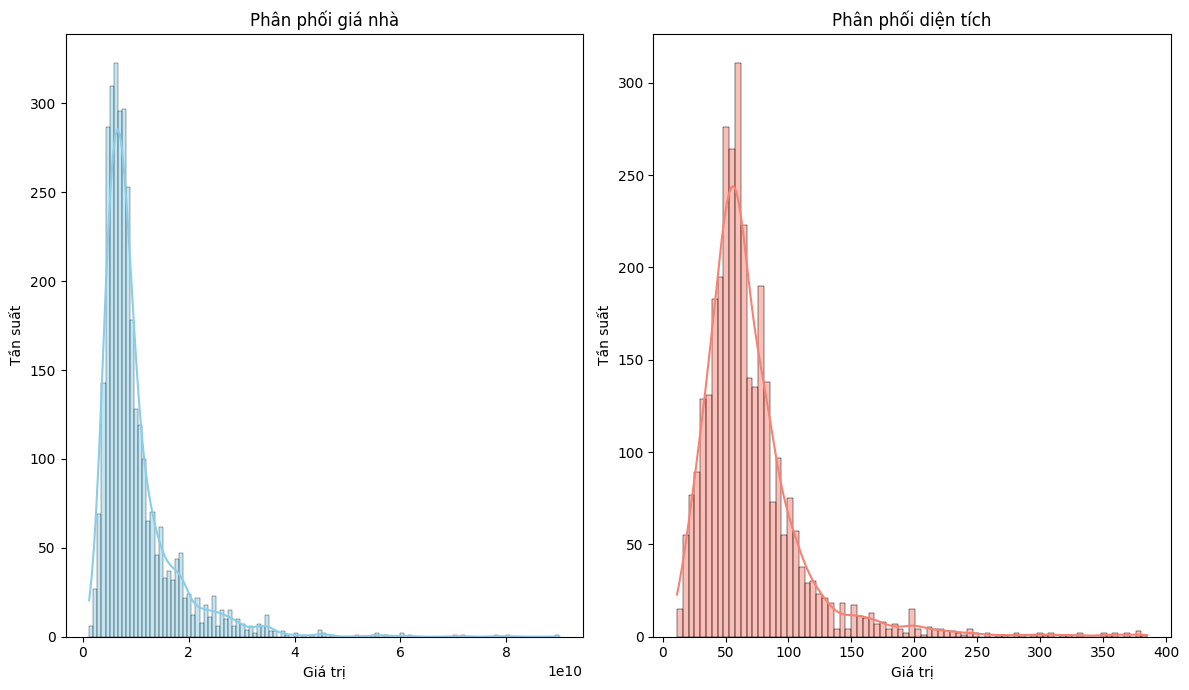

In [254]:
# Biểu đồ hist phân phối giá và diện tích
fig, axes = plt.subplots(1, 2, figsize=(12, 7))

sns.histplot(df['gia'], kde=True, color="skyblue", ax=axes[0])
axes[0].set_title('Phân phối giá nhà')
axes[0].set_xlabel('Giá trị')
axes[0].set_ylabel('Tần suất')

sns.histplot(df['dien_tich'], kde=True, color="salmon", ax=axes[1])
axes[1].set_title('Phân phối diện tích')
axes[1].set_xlabel('Giá trị')
axes[1].set_ylabel('Tần suất')

plt.tight_layout()
plt.savefig('hist_gia_dt.png')
plt.show()

Dựa trên các biểu đồ tần suất (Histogram), ta có cái nhìn tổng quan về hai biến quan trọng nhất:
* Giá nhà: Biểu đồ cho thấy sự phân tán rất lớn và bị lệch phải (right-skewed) rõ rệt. Phần lớn các giao dịch tập trung ở phân khúc giá thấp và trung bình, nhưng có một số ít bất động sản có giá trị cực cao (lên đến gần 80 tỷ VNĐ), tạo thành các điểm ngoại lệ (outliers).
* Diện tích: Tương tự như giá, diện tích nhà cũng có phân phối lệch phải. Đa số các căn nhà có diện tích phổ biến trong khoảng $50m^2$ đến $100m^2$. Việc dữ liệu bị lệch cho thấy cần cân nhắc các kỹ thuật chuẩn hóa (như Log-transform) trước khi đưa vào mô hình hồi quy để đạt độ chính xác cao hơn.
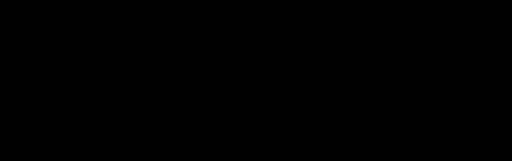

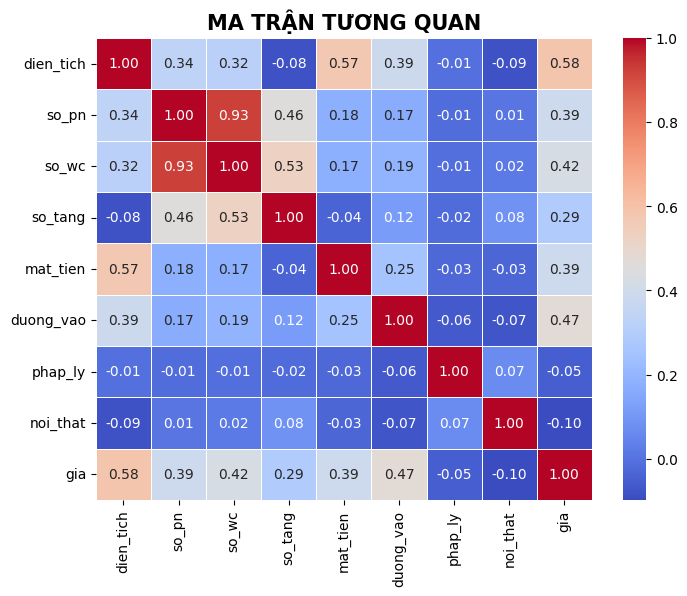

In [255]:
# Phân loại đặc trưng
numeric_features = ['dien_tich', 'so_pn', 'so_wc', 'so_tang', 'mat_tien', 'duong_vao', 'phap_ly', 'noi_that']
category_features = 'phuong_xa'
target = 'gia'

# Tính hệ số tương quan
corr_matrix = df[numeric_features + [target]].corr()
# Vẽ  heatmap ma trận tương quan
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('MA TRẬN TƯƠNG QUAN', size=15, fontweight='bold')
plt.savefig('corr_matrix.png')
plt.show()

Phân tích ma trận tương quan giữa các đặc trưng numeric và biến đầu ra, ta nhận thấy các yếu tố sau:
* Các đặc trưng *`phap_ly`, `noi_that`* có tương quan rất yếu với *`gia`* **(dưới 0.1**) $\Rightarrow$ Không chọn các đặc trưng này để huấn luyện mô hình
* 2 đặc trưng *`so_pn`* và *`so_wc`* có tương quan rất mạnh **(0.93)** $\Rightarrow$ Chỉ chọn 1 trong 2 đặc trưng để tránh đa cộng tuyến

<Figure size 1200x1000 with 0 Axes>

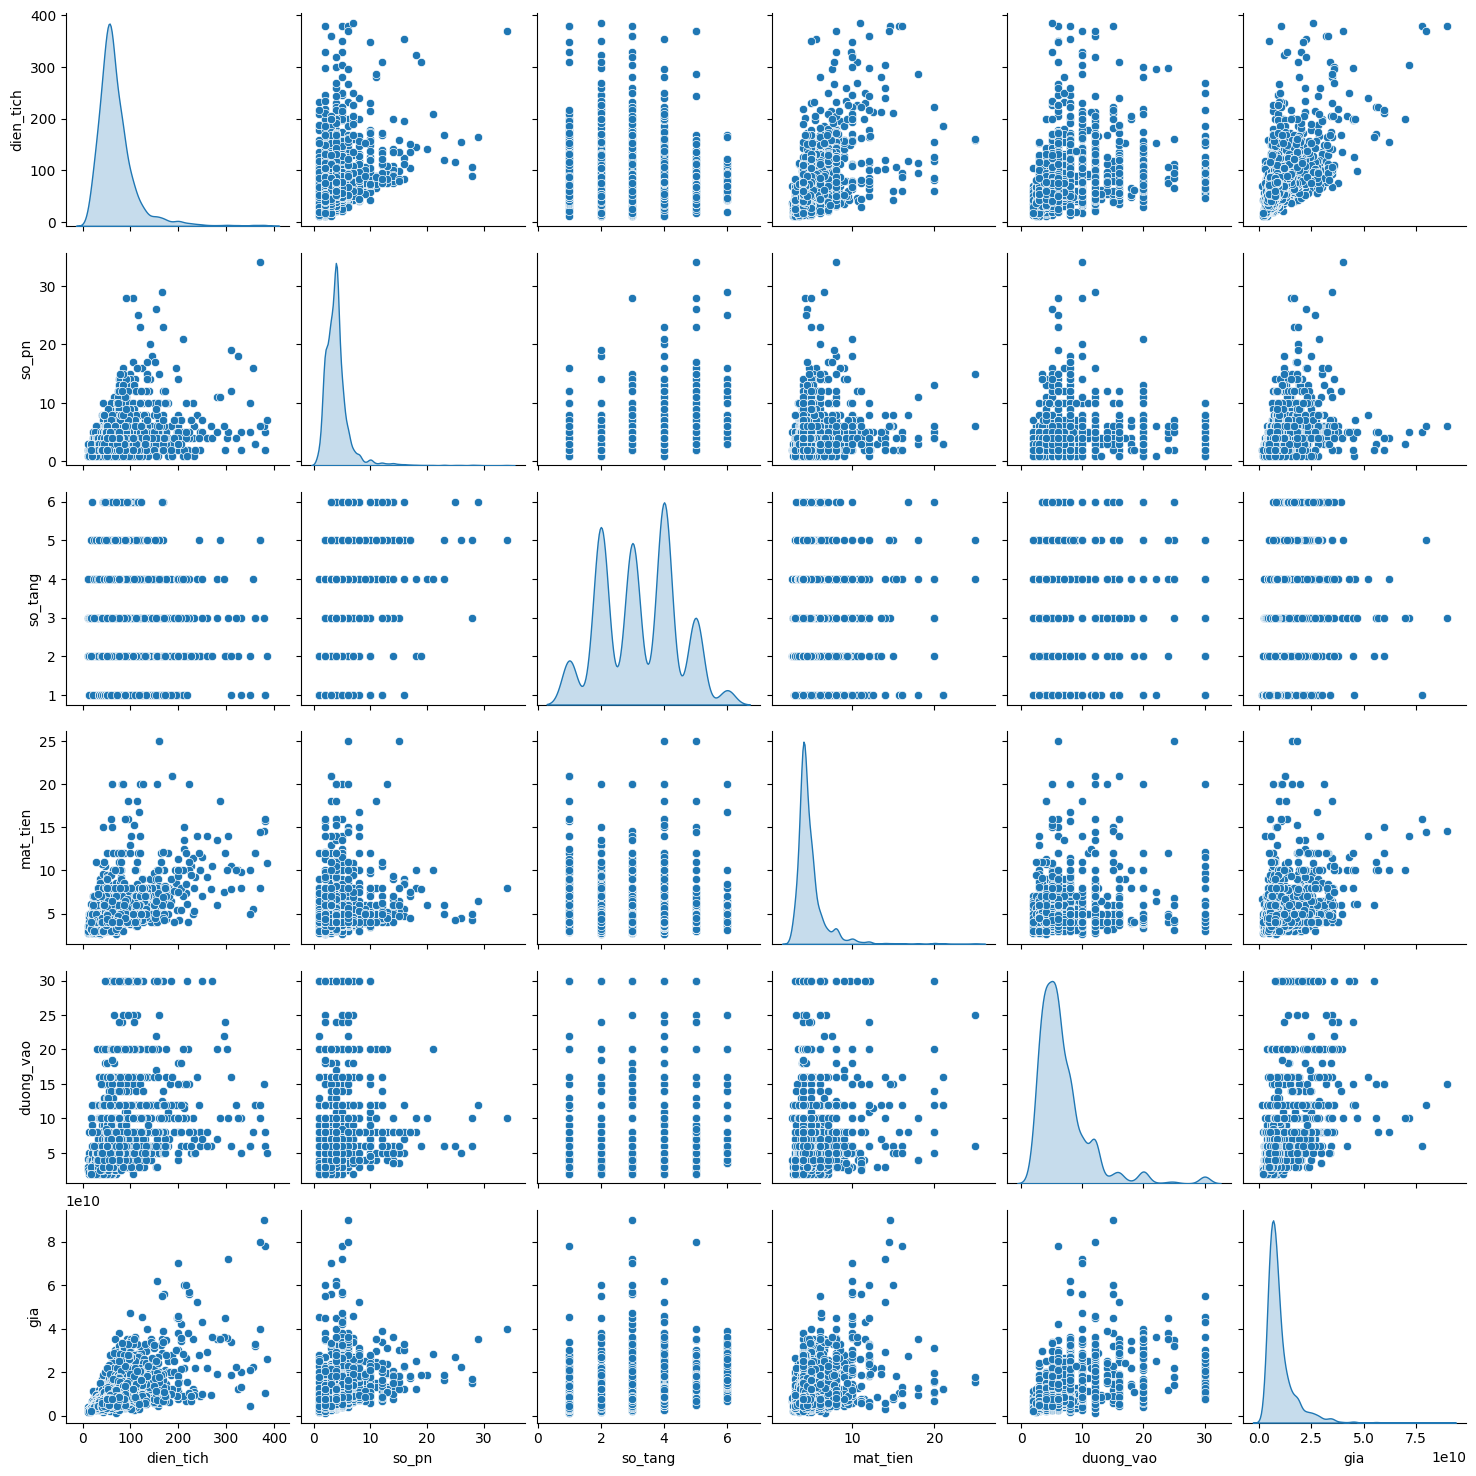

In [256]:
# Vẽ biểu đồ pairplot
selected_features = ['dien_tich', 'so_pn', 'so_tang', 'mat_tien', 'duong_vao']
plt.figure(figsize=(12,10))
sns.pairplot(df[selected_features + [target]],diag_kind='kde')
plt.savefig('pairplot.png')
plt.show()

Phân tích biểu đồ pairplot, ta nhận thấy các yếu tô sau:
* `dien_tich` vs `gia`: Có mối tương quan thuận rõ rệt nhất. Khi diện tích tăng, giá nhà có xu hướng tăng theo hình loa kèn (heteroscedasticity) – nghĩa là diện tích càng lớn thì sự biến động về giá càng cao.
* `so_pn` và `so_tang`: Các điểm dữ liệu tập trung thành các đường dọc do đây là biến rời rạc. Có sự tương quan thuận nhẹ với giá, nhưng không mạnh bằng diện tích.
* `mat_tien` và `duong_vao`: Có tác động đến giá nhưng độ phân tán (noise) rất lớn. Những căn có mặt tiền lớn hoặc đường vào rộng thường nằm ở phân khúc giá cao hơn.
* Hầu hết các biến (`dien_tich`, `gia`, `mat_tien`) đều có phân phối lệch phải (right-skewed). Đa số các bất động sản tập trung ở diện tích và giá trị nhỏ, chỉ có một số ít là "biệt thự" hoặc siêu bất động sản. $\Rightarrow$ lấy logarit để dữ liệu có phân phối chuẩn
* Biến `so_tang` có phân phối đa đỉnh, cho thấy các nhóm nhà phổ biến thường là 2, 3 hoặc 4 tầng.


In [266]:
num_unique = df['phuong_xa'].nunique()
print(f"Số lượng nhãn phường/xã: {num_unique}")
print(df['phuong_xa'].value_counts().to_string())

Số lượng nhãn phường/xã: 64
phuong_xa
Nhà Bè                                      252
Thông Tây Hội                               100
Bình Lợi Trung                               89
An Hội Tây                                   84
Bình Hưng Hòa                                77
Phú Nhuận                                    69
Bình Thạnh                                   68
Cầu Kiệu                                     67
An Phú Đông                                  67
Tân Bình                                     67
Tân Mỹ                                       65
Hiệp Bình                                    65
Phú Thuận                                    63
Phước Long/Tăng Nhơn Phú                     63
Thới An                                      61
Hiệp Phước                                   60
Bảy Hiền                                     60
Thủ Đức                                      59
Tân Thuận                                    58
Tân Sơn                                      56
Tâ

In [258]:
ket_qua = df.groupby('phuong_xa')['gia'].agg(['min', 'max', 'mean', 'median', 'count'])
ket_qua

,min,max,mean,median,count
phuong_xa,,,,,
An Hội Tây,3.400000e+09,2.000000e+10,7.628929e+09,6.985000e+09,84
An Hội Đông,2.250000e+09,3.500000e+10,7.600000e+09,5.955000e+09,36
An Khánh,1.050000e+10,9.000000e+10,3.532581e+10,3.000000e+10,31
An Lạc,3.350000e+09,3.400000e+10,8.881538e+09,6.680000e+09,39
An Nhơn,2.680000e+09,1.780000e+10,9.190000e+09,8.300000e+09,32
...,...,...,...,...,...
Vĩnh Lộc/Tân Nhựt/Bình Lợi,2.250000e+09,1.470000e+10,6.567857e+09,6.025000e+09,28
Vườn Lài,4.300000e+09,3.500000e+10,9.156341e+09,7.200000e+09,41
Xuân Hòa,4.680000e+09,3.500000e+10,1.590455e+10,1.390000e+10,33


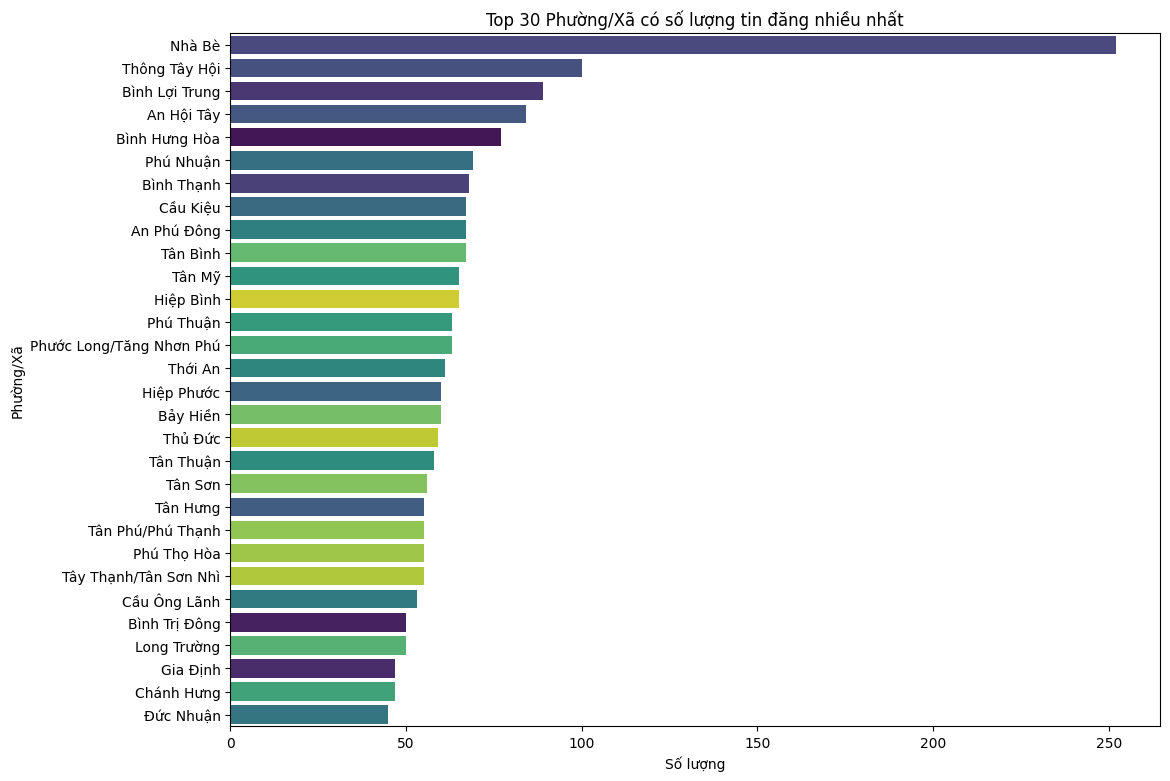

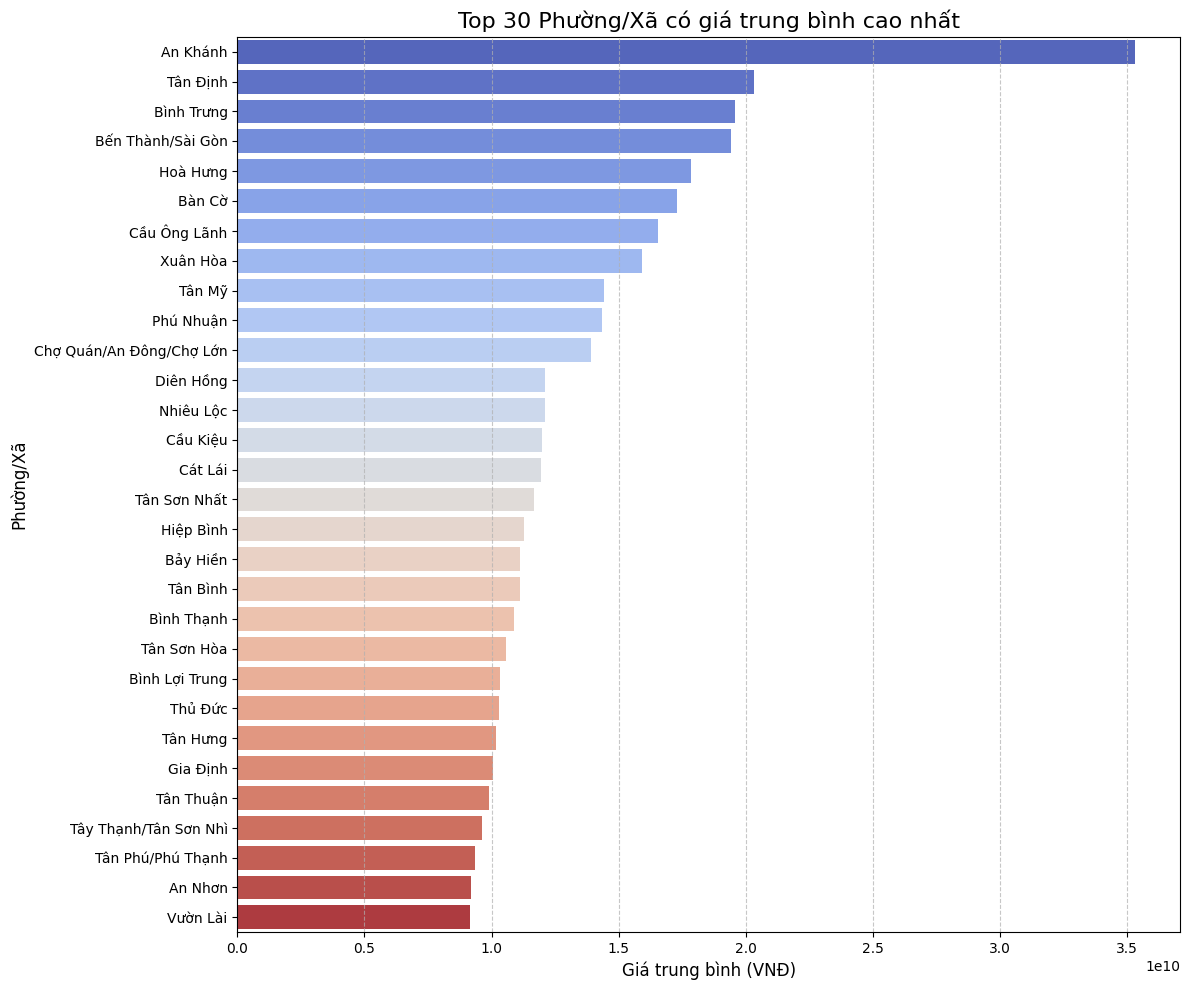

In [267]:
top_30_phuong = df['phuong_xa'].value_counts().nlargest(30).index

plt.figure(figsize=(12, 9))
sns.countplot(data=df[df['phuong_xa'].isin(top_30_phuong)], y='phuong_xa', order=top_30_phuong, palette='viridis', hue='phuong_xa', legend=False)
plt.title('Top 30 Phường/Xã có số lượng tin đăng nhiều nhất')
plt.xlabel('Số lượng')
plt.ylabel('Phường/Xã')
plt.savefig('phuong_xa_counts.png')

top_30_price = df.groupby('phuong_xa')['gia'].mean().sort_values(ascending=False).head(30)


plt.figure(figsize=(12, 10))

sns.barplot(
    x=top_30_price.values,
    y=top_30_price.index,
    palette='coolwarm',
    hue=top_30_price.index,
    legend=False
)

plt.title('Top 30 Phường/Xã có giá trung bình cao nhất', fontsize=16)
plt.xlabel('Giá trung bình (VNĐ)', fontsize=12)
plt.ylabel('Phường/Xã', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('phuong_xa_mean_price_top30.png')
plt.show()

Dữ liệu cho thấy một sự phân hóa rõ rệt về cả số lượng tin đăng và giá trị trung bình giữa các khu vực:
* Về số lượng: Có sự tập trung cực kỳ cao vào một số ít khu vực (Top 5 chiếm tỷ trọng lớn), trong khi có tới 89 phường/xã nhưng nhiều nơi chỉ có 1-2 tin đăng.
* Về giá trị: Những nơi có giá trung bình cao nhất (như An Khánh, Tân Định, Bình Trưng, ...) lại không phải là những nơi có lượng tin đăng nhiều nhất. Điều này cho thấy phân khúc bất động sản cao cấp thường có tính thanh khoản thấp hơn hoặc khan hiếm hơn trên thị trường tin rao.
* Với 251 tin đăng (gấp 2.5 lần khu vực đứng thứ hai là Thông Tây Hội), Nhà Bè đang là tâm điểm của dữ liệu này. Lý do có thể bao gồm:
    * Quỹ đất và dự án mới: Nhà Bè là khu vực đang trong quá trình đô thị hóa mạnh mẽ với nhiều dự án chung cư và đất nền mới. Mỗi dự án mở bán thường tạo ra một làn sóng tin rao khổng lồ từ cả chủ đầu tư và môi giới.
    * Phân khúc giá dễ tiếp cận: Nhìn vào biểu đồ giá, Nhà Bè nằm ở nhóm dưới (khoảng 7-8 tỷ VNĐ trung bình), đây là phân khúc "vừa túi tiền" với số đông, dẫn đến giao dịch sôi động và lượng tin đăng dày đặc.
    * Đặc điểm dữ liệu: Có khả năng dữ liệu được thu thập từ các trang web mà tại thời điểm đó, các dự án ở Nhà Bè đang chạy chiến dịch quảng cáo mạnh.

$\Rightarrow$ `phuong_xa` (yếu tố địa lý) là một đặc trưng quan trọng ảnh hướng đến giá nhà.

Bộ dữ liệu có sự chênh lệch về mẫu tin ở các Phường khác nhau tuy có thể phản ánh đúng thực tế thị trường nhưng cũng có các hạn chế khi xây dựng mô hình:
* Sai số lớn ở nhóm "thiểu số": Với các phường chỉ có 1-2 tin đăng (như Xuân Thới Sơn, Bình Tiên), mô hình không có đủ dữ liệu để học. Dự đoán tại đây dễ bị nhiễu hoặc bị kéo theo xu hướng chung của toàn bộ dữ liệu.
* Mô hình có xu hướng "ghi nhớ" giá của Nhà Bè thay vì học cách tính toán giá dựa trên các đặc điểm diện tích, vị trí.

# Biện luận chọn đặc trưng và mô hình

## Về biến mục tiêu
Nhóm chọn phương pháp log-transform cho biến `gia` để dữ liệu hướng về phân phối chuẩn
## Về đặc trưng
Từ các phân tích thăm dò trên, nhóm xác định các đặc trưng có thể đưa vào mô hình:
* `dien_tich`: log-tranform để có phân phối chuẩn.
* `so_pn`, `mat_tien`, `duong_vao`, `so_tang`: Là các đặc điểm về cấu trúc sẽ ảnh hưởng đến giá nhà.
* `phuong_xa`: Là đặc điểm về địa lý, cũng là một yếu tố ảnh hưởng rất lớn đến giá bất động sản. Tuy nhiên, dữ liệu có sự mất cân bằng lớn giữa các khu vực (Nhà Bè chiếm ưu thế), do đó nhóm nghiên cứu đã các phường ít tin với khu vực lân cận  và Target Encoding có Smoothing để đảm bảo mô hình không bị thiên kiến (bias) và đạt độ tổng quát hóa tốt hơn.

Các biến không được chọn vào mô hình gồm:
* `phap_ly`, `noi_that`: các biến này có độ lệch dữ liệu quá lớn nên hầu như không thể hiện mối tương quan nào tới giá trị nhà.
* `so_wc`: tương quan rất mạnh với số phòng ngủ nên sẽ loại bỏ để tránh đa cộng tuyến.
## Về mô hình:
Nhóm chọn các mô hình sau để huấn luyện và so sánh để tìm ra mô hình tối ưu nhất với việc dự đoán giá nhà.
* Hồi quy tuyến tính (LinearRegression): mô hình đơn giản, làm mốc chuẩn để so sánh
* Lasso Regression: Cải tiến của Linear Regression
* K-Nearest Neighbors (KNN Regressor): Dựa trên nguyên lý "Nhà gần nhau/giống nhau thì giá xấp xỉ nhau
* Random Forest Regressor: Mô hình phi tuyến tính mạnh mẽ, xử lý tốt các biến rời rạc, chống chịu tốt với Outliers và Nhiễu
* XGBoost: Sử dụng kỹ thuật Gradient Boosting mạnh mẽ, tập trung tối ưu hóa các sai số từ các cây trước đó. Đây là "tiêu chuẩn vàng" trong các cuộc thi dữ liệu nhờ tốc độ và khả năng kiểm soát phương sai tốt.
* CatBoost có thuật toán xử lý biến Category đặc thù, giúp chuyển đổi các nhãn này thành giá trị số mà không làm mất đi thông tin về thứ tự hay quan hệ không gian, từ đó hạn chế tối đa Overfitting

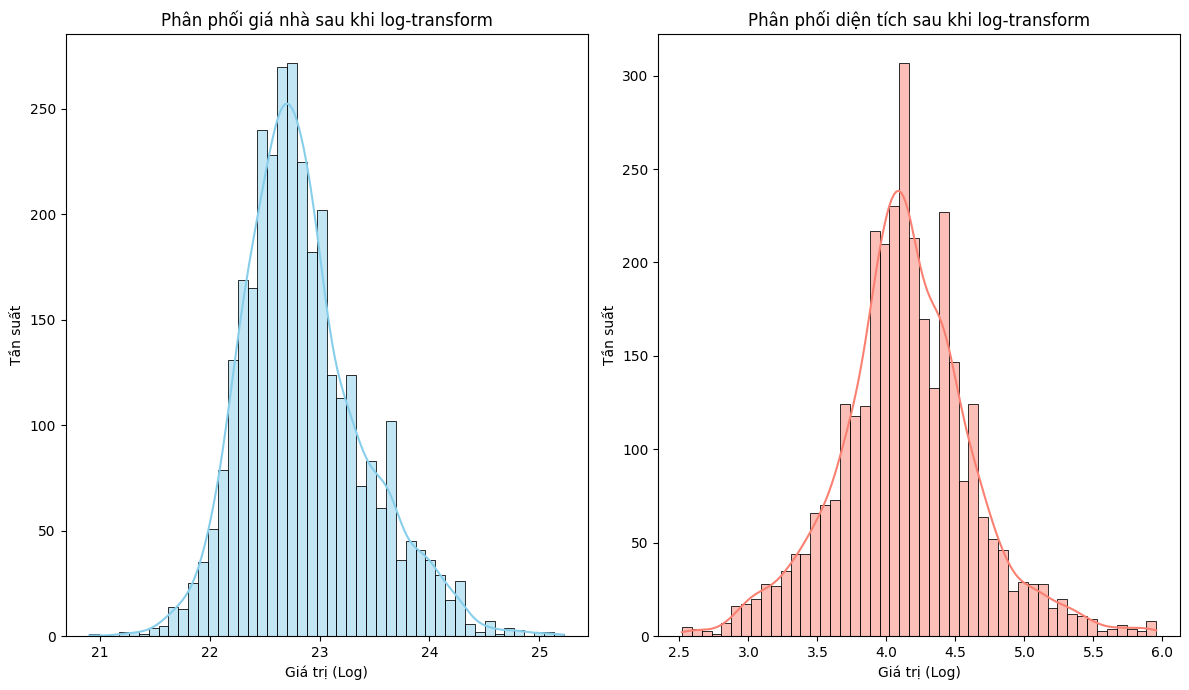

In [260]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7))

sns.histplot(np.log1p(df['gia']), kde=True, color="skyblue", ax=axes[0])
axes[0].set_title('Phân phối giá nhà sau khi log-transform')
axes[0].set_xlabel('Giá trị (Log)')
axes[0].set_ylabel('Tần suất')

sns.histplot(np.log1p(df['dien_tich']), kde=True, color="salmon", ax=axes[1])
axes[1].set_title('Phân phối diện tích sau khi log-transform')
axes[1].set_xlabel('Giá trị (Log)')
axes[1].set_ylabel('Tần suất')

plt.tight_layout()
plt.savefig('hist_log_gia_dt.png')
plt.show()

# Phát triển mô hình

In [261]:
from sklearn.base import RegressorMixin

class CustomTargetEncoder(BaseEstimator, TransformerMixin):
    """Target Encoding with Smoothing"""
    def __init__(self, smoothing=10):
        self.smoothing = smoothing
        self.encoding_map_ = None
        self.global_mean_ = None

    def fit(self, X, y):
        # Lưu ý: y ở đây đã được log-transform từ bên ngoài nếu dùng trong pipeline
        X_series = pd.Series(X.ravel())
        y_series = pd.Series(y)

        # Tính toán thống kê
        stats = pd.DataFrame({'group': X_series, 'target': y_series})
        agg = stats.groupby('group')['target'].agg(['count', 'mean'])
        self.global_mean_ = y_series.mean()

        # Công thức Smoothing
        # w_i = n_i / (n_i + m)
        # encoded = w_i * mu_i + (1 - w_i) * mu_global
        smoothing_factor = agg['count'] / (agg['count'] + self.smoothing)
        self.encoding_map_ = smoothing_factor * agg['mean'] + (1 - smoothing_factor) * self.global_mean_
        return self

    def transform(self, X):
        X_series = pd.Series(X.ravel())
        return X_series.map(self.encoding_map_).fillna(self.global_mean_).values.reshape(-1, 1)

class CatBoostWrapper(BaseEstimator, RegressorMixin):
    """
    Wrapper để sửa lỗi tương thích __sklearn_tags__ giữa Scikit-learn 1.6+ và CatBoost
    """
    def __init__(self, iterations=1000, learning_rate=0.05, random_state=3, cat_features=None, verbose=0):
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.random_state = random_state
        self.cat_features = cat_features
        self.verbose = verbose
        self.model_ = None

    def fit(self, X, y):
        self.model_ = CatBoostRegressor(
            iterations=self.iterations,
            learning_rate=self.learning_rate,
            random_state=self.random_state,
            cat_features=self.cat_features,
            verbose=self.verbose,
            allow_writing_files=False
        )
        self.model_.fit(X, y)
        return self

    def predict(self, X):
        return self.model_.predict(X)
def log_transform_feature(X):
    """Hàm log transform an toàn (log1p)"""
    return np.log1p(X)

Model                | RMSE         | R2       | Adj R2   | MAE          | MAPE    
-------------------------------------------------------------------------------------
LinearRegression     | 4,626,580,994 | 0.5075   | 0.5045   | 2,826,198,804 | 28.21%
Lasso                | 4,629,291,752 | 0.5069   | 0.5039   | 2,824,470,162 | 28.19%
KNN                  | 4,552,694,387 | 0.5231   | 0.5202   | 2,706,913,676 | 26.43%
RandomForest         | 3,894,668,104 | 0.6510   | 0.6489   | 2,176,557,564 | 21.24%
XGBoost              | 2,884,427,424 | 0.8086   | 0.8074   | 1,556,624,628 | 14.80%
CatBoost             | 2,735,288,996 | 0.8279   | 0.8268   | 1,505,561,037 | 14.17%


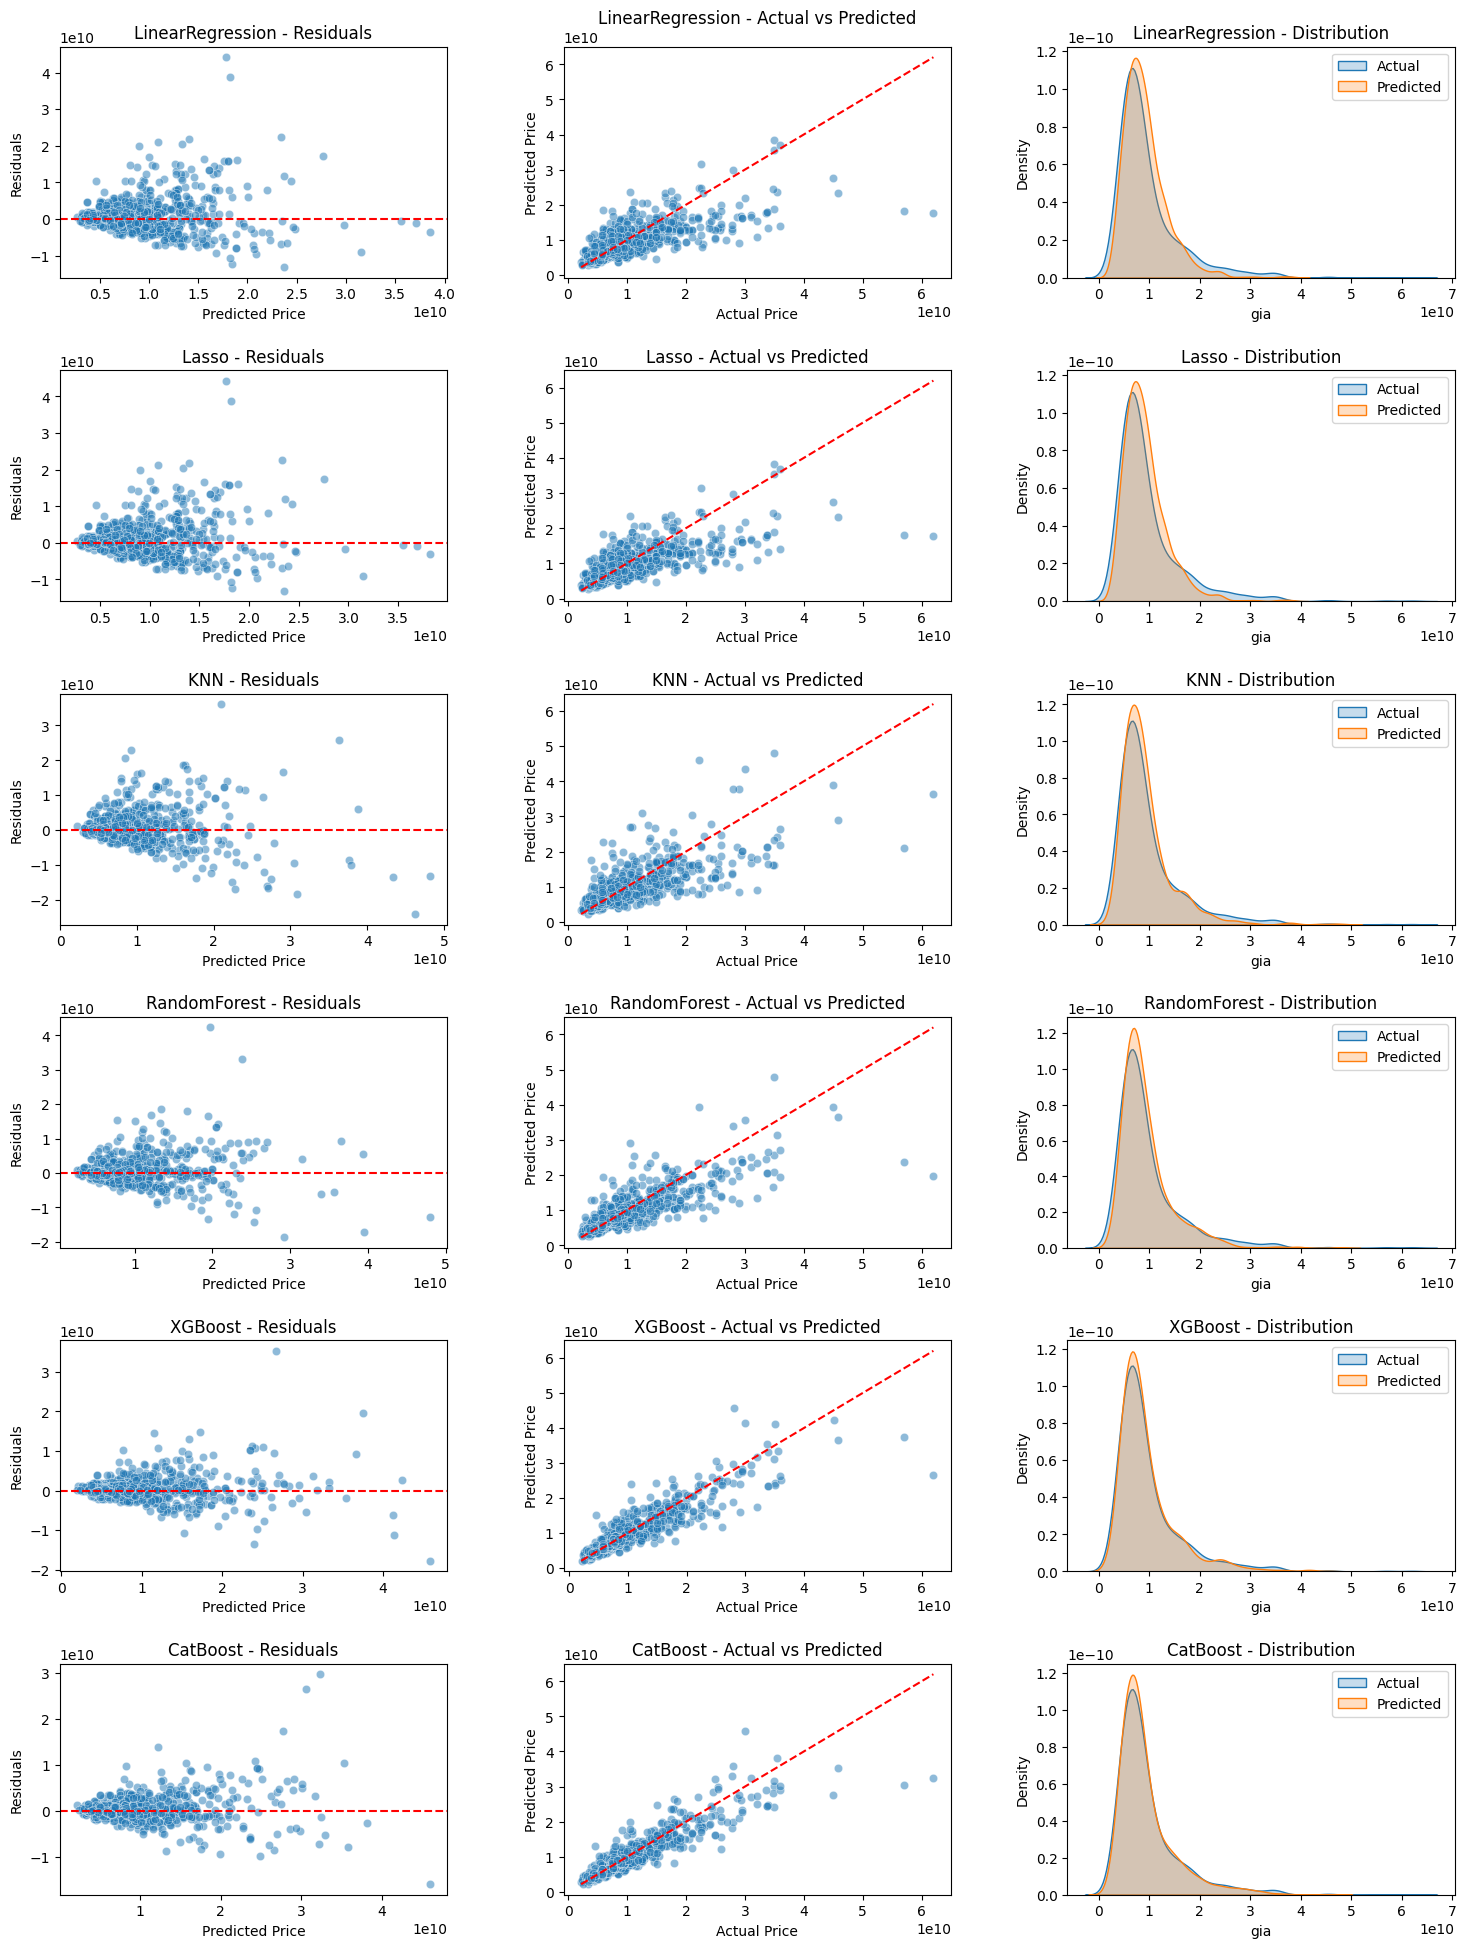

In [262]:
X = df[selected_features+['phuong_xa']]
y = df['gia']

# Log transform Target 'gia' ngay từ đầu (như yêu cầu)
y_log = np.log1p(y)

# Chia Train-Test (7-3), RandomState=3
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.3, random_state=3
)
phuong_xa_counts = X_train['phuong_xa'].value_counts().to_dict()

# --- Pipeline cho mô hình thường (Linear, KNN, RF, XGB) ---
preprocessor_general = ColumnTransformer(transformers=[
    # Dien tich: Log transform
    ('log_dt', FunctionTransformer(log_transform_feature), ['dien_tich']),

    # Phuong xa: Group rare -> Target Encode
    ('cat_px', Pipeline([
        ('encoder', CustomTargetEncoder(smoothing=10)),
    ]), ['phuong_xa']),

    # Các biến còn lại: Passthrough
    ('others', 'passthrough', ['duong_vao', 'mat_tien', 'so_tang', 'so_pn'])
])

# Pipeline thêm Scaling cho Linear/KNN
pipeline_linear_knn = Pipeline([
    ('preprocessor', preprocessor_general),
    ('scaler', StandardScaler()) # Quan trọng cho KNN và Lasso
])

# Pipeline cho Tree (RF, XGB) - Không cần Scaling
pipeline_tree = Pipeline([
    ('preprocessor', preprocessor_general)
])

# Pipeline cho CatBoost
preprocessor_catboost = ColumnTransformer(transformers=[
    ('log_dt', FunctionTransformer(log_transform_feature), ['dien_tich']),
    ('others', 'passthrough', ['duong_vao', 'mat_tien', 'so_tang', 'so_pn'])
])

# MODEL DEFINITIONS

models = {
    "LinearRegression": Pipeline([
        ('prep', pipeline_linear_knn),
        ('model', LinearRegression())
    ]),

    "Lasso": Pipeline([
        ('prep', pipeline_linear_knn),
        ('model', Lasso(alpha=0.001, random_state=3))
    ]),

    "KNN": Pipeline([
        ('prep', pipeline_linear_knn),
        ('model', KNeighborsRegressor(n_neighbors=5))
    ]),

    "RandomForest": Pipeline([
        ('prep', pipeline_tree),
        ('model', RandomForestRegressor(n_estimators=100, random_state=3))
    ]),

    "XGBoost": Pipeline([
        ('prep', pipeline_tree),
        ('model', XGBRegressor(n_estimators=1000, learning_rate=0.05, random_state=3, n_jobs=-1))
    ]),

    "CatBoost": Pipeline([
        ('prep', preprocessor_catboost),
        # CatBoost cần biết cột nào là categorical (cột index 1 sau khi transform: dien_tich(0), phuong_xa(1), others...)
        ('model', CatBoostWrapper(iterations=1000, learning_rate=0.05,
                                    cat_features=[1], # Chỉ định cột phuong_xa sau khi qua preprocessor là category
                                    verbose=0, random_state=3))
    ])
}

# EVALUATION & PLOTTING

results = {}

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

fig, axes = plt.subplots(6, 3, figsize=(18, 24))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

print(f"{'Model':<20} | {'RMSE':<12} | {'R2':<8} | {'Adj R2':<8} | {'MAE':<12} | {'MAPE':<8}")
print("-" * 85)

for i, (name, model) in enumerate(models.items()):
    # Train
    model.fit(X_train, y_train_log)

    # Predict (trên log scale)
    y_pred_log = model.predict(X_test)

    # Inverse Transform (đưa về giá thực tế để tính metrics cho dễ cảm nhận)
    y_true = np.expm1(y_test_log)
    y_pred = np.expm1(y_pred_log)

    # Calculate Metrics
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    adj_r2 = adjusted_r2(r2, X_test.shape[0], X_test.shape[1])
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)

    results[name] = {'RMSE': rmse, 'R2': r2, 'Adj R2': adj_r2}
    print(f"{name:<20} | {rmse:,.0f} | {r2:.4f}   | {adj_r2:.4f}   | {mae:,.0f} | {mape:.2%}")

    # Plotting
    # Row i, Col 0: Residual Plot
    residuals = y_true - y_pred
    sns.scatterplot(x=y_pred, y=residuals, ax=axes[i, 0], alpha=0.5)
    axes[i, 0].axhline(0, color='r', linestyle='--')
    axes[i, 0].set_title(f'{name} - Residuals')
    axes[i, 0].set_xlabel('Predicted Price')
    axes[i, 0].set_ylabel('Residuals')

    # Row i, Col 1: Actual vs Predicted
    sns.scatterplot(x=y_true, y=y_pred, ax=axes[i, 1], alpha=0.5)
    max_val = max(y_true.max(), y_pred.max())
    min_val = min(y_true.min(), y_pred.min())
    axes[i, 1].plot([min_val, max_val], [min_val, max_val], 'r--') # Đường chéo
    axes[i, 1].set_title(f'{name} - Actual vs Predicted')
    axes[i, 1].set_xlabel('Actual Price')
    axes[i, 1].set_ylabel('Predicted Price')

    # Row i, Col 2: Distribution Comparison
    sns.kdeplot(y_true, label='Actual', ax=axes[i, 2], fill=True)
    sns.kdeplot(y_pred, label='Predicted', ax=axes[i, 2], fill=True)
    axes[i, 2].set_title(f'{name} - Distribution')
    axes[i, 2].legend()

plt.savefig('model_report.png')
plt.show()

# Đặc trưng quan trọng

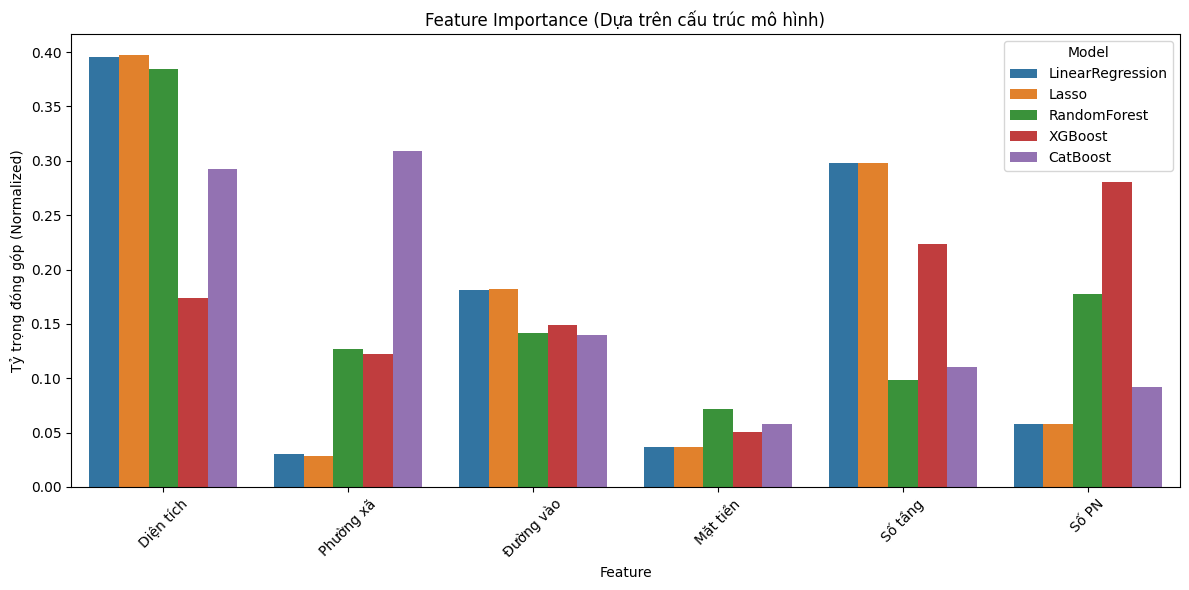

In [263]:
from sklearn.inspection import permutation_importance
feature_names = [
    'Diện tích',    # Index 0
    'Phường xã',    # Index 1
    'Đường vào',    # Index 2
    'Mặt tiền',     # Index 3
    'Số tầng',      # Index 4
    'Số PN'         # Index 5
]

# PHƯƠNG PHÁP 1: TRÍCH XUẤT TRỰC TIẾP (COEF / GINI IMPORTANCE)
df_imp_native = []

for name, pipeline in models.items():
    # Lấy step model cuối cùng ra
    model_step = pipeline.named_steps['model']

    importances = None

    # TRƯỜNG HỢP 1: CatBoostWrapper (Lấy từ biến nội bộ model_)
    if hasattr(model_step, 'model_') and hasattr(model_step.model_, 'feature_importances_'):
        importances = model_step.model_.feature_importances_

    # TRƯỜNG HỢP 2: Tree Models chuẩn (RandomForest, XGBoost)
    elif hasattr(model_step, 'feature_importances_'):
        importances = model_step.feature_importances_

    # TRƯỜNG HỢP 3: Linear Models (Dùng hệ số Coef)
    elif hasattr(model_step, 'coef_'):
        importances = np.abs(model_step.coef_)

    else:
        continue # Bỏ qua KNN hoặc model lỗi

    # Chuẩn hóa về % để dễ so sánh
    if importances is not None:
        importances = importances / np.sum(importances)
        for feat, imp in zip(feature_names, importances):
            df_imp_native.append({
                'Model': name,
                'Feature': feat,
                'Importance': imp
            })

# Vẽ biểu đồ
if df_imp_native:
    df_native = pd.DataFrame(df_imp_native)
    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_native, x='Feature', y='Importance', hue='Model')
    plt.title('Feature Importance (Dựa trên cấu trúc mô hình)')
    plt.ylabel('Tỷ trọng đóng góp (Normalized)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

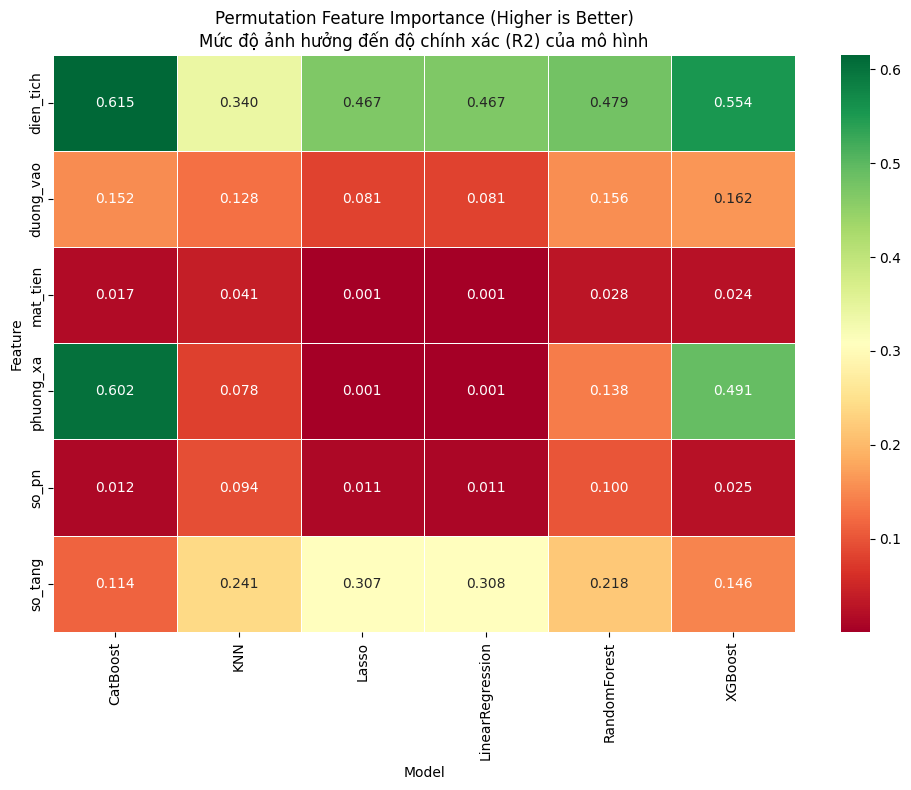

In [264]:
# PHƯƠNG PHÁP 2: PERMUTATION IMPORTANCE
df_imp_perm = []

# Duyệt qua từng mô hình
for name, model in models.items():
    # Tính toán tầm quan trọng
    result = permutation_importance(
        model, X_test, y_test_log,
        n_repeats=10,
        random_state=42,
        n_jobs=-1,
        scoring='r2'
    )

    for i, feat in enumerate(X_test.columns):
        df_imp_perm.append({
            'Model': name,
            'Feature': feat,
            'Importance': result.importances_mean[i]  # <--- SỬA LỖI TẠI ĐÂY (Thêm [i])
        })

# Vẽ biểu đồ Heatmap
if df_imp_perm:
    df_perm = pd.DataFrame(df_imp_perm)

    # Pivot bảng dữ liệu để vẽ Heatmap
    pivot_perm = df_perm.pivot(index='Feature', columns='Model', values='Importance')

    plt.figure(figsize=(10, 8))
    sns.heatmap(pivot_perm, annot=True, cmap='RdYlGn', fmt='.3f', linewidths=0.5)
    plt.title('Permutation Feature Importance (Higher is Better)\nMức độ ảnh hưởng đến độ chính xác (R2) của mô hình')
    plt.tight_layout()
    plt.show()